# 天猫优惠券使用客群预测

## 1. 业务问题

为了提高优惠券的使用率，根据用户的年龄、婚姻、职业、贷款等属性，以及过去是否用过优惠券的行为，预测每个用户是否会使用优惠券，从而把券优先发给模型预测用券概率高的用户，并通过实验验证发券是否真的带来额外消费。

## 2. 数据概况与清洗

检查框架：结构 → 完整性 → 一致性 → 准确性（异常值）→ 目标列分布

In [1]:
import pandas as pd

# 读取数据（data/ 不上传 GitHub，见 README）
df = pd.read_csv('data/tianmao.csv')

### 2.1 结构：多少行、多少列、每列是什么类型

In [2]:
print(df.shape)
df.info()
df.head()

(25317, 10)
<class 'pandas.DataFrame'>
RangeIndex: 25317 entries, 0 to 25316
Data columns (total 10 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   ID                          25317 non-null  int64
 1   age                         25317 non-null  int64
 2   job                         25317 non-null  str  
 3   marital                     25317 non-null  str  
 4   default                     25317 non-null  str  
 5   returned                    25317 non-null  str  
 6   loan                        25317 non-null  str  
 7   coupon_used_in_last6_month  25317 non-null  int64
 8   coupon_used_in_last_month   25317 non-null  int64
 9   coupon_ind                  25317 non-null  int64
dtypes: int64(5), str(5)
memory usage: 1.9 MB


,ID,age,job,marital,default,returned,loan,coupon_used_in_last6_month,coupon_used_in_last_month,coupon_ind
0,1,43,management,married,no,yes,no,2,0,0
1,2,42,technician,divorced,no,yes,no,1,1,0
2,3,47,admin.,married,no,yes,yes,2,0,0
3,4,28,management,single,no,yes,yes,2,0,0
4,5,42,technician,divorced,no,yes,no,5,0,0


**你的结论：**
数据集非常的完整，10列，字段类型是int64,str

### 2.2 完整性：空值，以及“等于没填”的隐藏缺失

In [3]:
# 真正的空值
print(df.isna().sum())

# 类别列的所有取值：留意有没有表示“未知”的取值
for col in ['job', 'marital', 'default', 'returned', 'loan']:
    print(col, df[col].value_counts().to_dict())

ID                            0
age                           0
job                           0
marital                       0
default                       0
returned                      0
loan                          0
coupon_used_in_last6_month    0
coupon_used_in_last_month     0
coupon_ind                    0
dtype: int64
job {'blue-collar': 5456, 'management': 5296, 'technician': 4241, 'admin.': 2909, 'services': 2342, 'retired': 1273, 'self-employed': 884, 'entrepreneur': 856, 'unemployed': 701, 'housemaid': 663, 'student': 533, 'unknown': 163}
marital {'married': 15245, 'single': 7157, 'divorced': 2915}
default {'no': 24869, 'yes': 448}
returned {'yes': 14020, 'no': 11297}
loan {'no': 21258, 'yes': 4059}


**你的结论：**
163 个 unknown，约占 0.6%，作为单独类别保留，不删除，也不猜测填补

### 2.3 一致性 / 重复

In [4]:
# ID 是否唯一
print('ID 重复数：', df['ID'].duplicated().sum())

# 去掉 ID 后完全相同的行有多少
print('去掉 ID 后的重复行：', df.drop(columns='ID').duplicated().sum())

ID 重复数： 0
去掉 ID 后的重复行： 11674


**你的结论：** 这些重复行是脏数据，还是自然现象？
自然现象。首先id列没有任何重复，代表每一行都是唯一的，删掉id列后，虽然由于每列选项很少导致很多一样，但他们本质依然是不同的人，盲目去重只会删掉真实数据

### 2.4 准确性：数值列的范围和异常值

In [5]:
# 看 min / max / 分位数，判断有没有现实中不太可能的值
df.describe()

,ID,age,coupon_used_in_last6_month,coupon_used_in_last_month,coupon_ind
count,25317.000000,25317.000000,25317.000000,25317.000000,25317.000000
mean,12659.000000,40.935379,2.772050,0.292847,0.116957
std,7308.532719,10.634289,3.136097,0.765498,0.321375
min,1.000000,18.000000,1.000000,0.000000,0.000000
25%,6330.000000,33.000000,1.000000,0.000000,0.000000
50%,12659.000000,39.000000,2.000000,0.000000,0.000000
75%,18988.000000,48.000000,3.000000,0.000000,0.000000
max,25317.000000,95.000000,55.000000,15.000000,1.000000


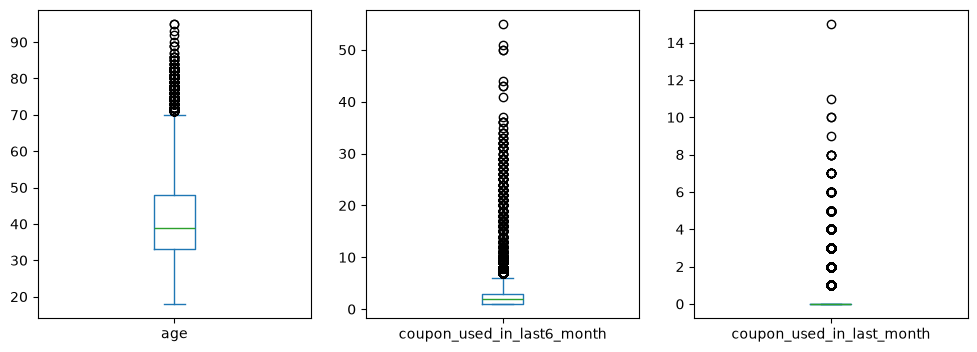

In [6]:
# 箱线图：一眼看出离群点
df[['age', 'coupon_used_in_last6_month', 'coupon_used_in_last_month']].plot(
    kind='box', subplots=True, layout=(1, 3), figsize=(12, 4));

**你的结论：** 有没有异常值？删、截断还是保留？为什么？
有，三张图都有，但全部保留。离群点并不意味着数据错了。95 岁、半年用 55 次券，虽然很离谱，但现实中依然有可能，可能是合理的极端用户，第三张图里用过券的人被画成圆圈，是因为一半人是 0 次，分布偏，不是异常。

### 2.5 目标列分布：样本是否平衡

In [7]:
# 用券(1) / 不用券(0) 的人数和占比
print(df['coupon_ind'].value_counts())
print(df['coupon_ind'].value_counts(normalize=True))

coupon_ind
0    22356
1     2961
Name: count, dtype: int64
coupon_ind
0    0.883043
1    0.116957
Name: proportion, dtype: float64


**你的结论：** 这个比例会影响后面的什么？
样本不平衡，会影响后续建模，让模型偏向多数类，偏向不使用券

## 3. 单变量 / 相关分析

思路：
- 类别型（job、marital、default、returned、loan）：按类别分组算用券率 + 柱状图，再用卡方检验判断差异是不是偶然
- 数值型（age、两列用券次数）：用券组 vs 没用券组，比较均值和中位数，并做两组检验；年龄再分段，按类别型的方法算各段用券率

注意：样本有 2.5 万行，p 值很容易很小，判断重要不重要主要看用券率差距有多大。

In [8]:
from scipy.stats import chi2_contingency, mannwhitneyu
import matplotlib.pyplot as plt

# 让图表能显示中文
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei']
plt.rcParams['axes.unicode_minus'] = False

# 整体用券率，作为比较基准
base_rate = df['coupon_ind'].mean()
print(f'整体用券率：{base_rate:.1%}')

def cramers_v(x, y):
    # Cramér's V：把卡方值换算成 0–1 的关联强度，不受样本量影响，越大关联越强
    table = pd.crosstab(x, y)
    chi2 = chi2_contingency(table)[0]
    n = table.values.sum()
    return (chi2 / (n * (min(table.shape) - 1))) ** 0.5

整体用券率：11.7%


### 3.1 类别型变量：各类别的用券率 + 卡方检验

In [9]:
cat_cols = ['job', 'marital', 'default', 'returned', 'loan']

for col in cat_cols:
    # 每个类别的用券率和人数（0/1 列的均值就是用券率）
    rate = df.groupby(col)['coupon_ind'].agg(用券率='mean', 人数='size').sort_values('用券率', ascending=False)
    # 卡方检验：类别 vs 是否用券
    chi2, p, dof, _ = chi2_contingency(pd.crosstab(df[col], df['coupon_ind']))
    print(f'===== {col}  卡方 p 值 = {p:.2e}  Cramér\'s V = {cramers_v(df[col], df["coupon_ind"]):.3f} =====')
    print(rate.round(3), '\n')

===== job  卡方 p 值 = 1.67e-94  Cramér's V = 0.137 =====
                 用券率    人数
job                       
student        0.268   533
retired        0.234  1273
unemployed     0.163   701
management     0.139  5296
unknown        0.123   163
self-employed  0.119   884
admin.         0.117  2909
technician     0.113  4241
services       0.090  2342
housemaid      0.087   663
entrepreneur   0.078   856
blue-collar    0.071  5456 

===== marital  卡方 p 值 = 2.17e-20  Cramér's V = 0.060 =====
            用券率     人数
marital               
single    0.146   7157
divorced  0.119   2915
married   0.103  15245 

===== default  卡方 p 值 = 1.22e-04  Cramér's V = 0.024 =====
           用券率     人数
default              
no       0.118  24869
yes      0.058    448 

===== returned  卡方 p 值 = 2.46e-115  Cramér's V = 0.143 =====
            用券率     人数
returned              
no        0.168  11297
yes       0.076  14020 

===== loan  卡方 p 值 = 4.08e-25  Cramér's V = 0.065 =====
        用券率     人数
loan      

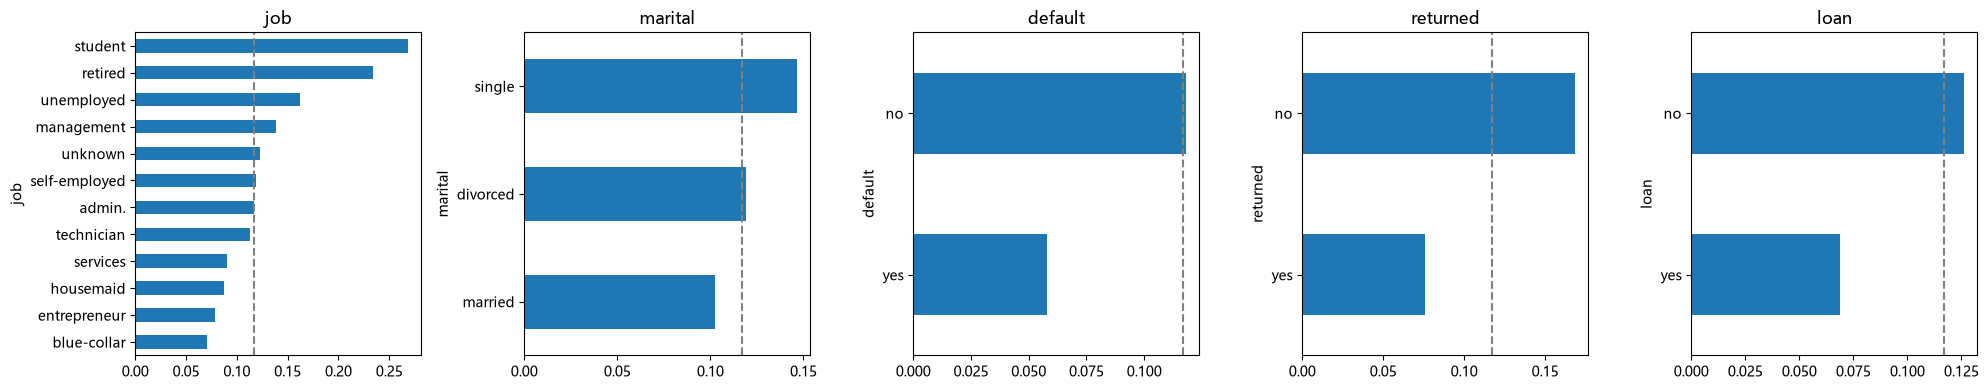

In [10]:
# 柱状图：每个类别的用券率，虚线是整体用券率
fig, axes = plt.subplots(1, len(cat_cols), figsize=(20, 4))
for ax, col in zip(axes, cat_cols):
    df.groupby(col)['coupon_ind'].mean().sort_values().plot(kind='barh', ax=ax, title=col)
    ax.axvline(base_rate, color='grey', linestyle='--')
plt.tight_layout()

**你的结论：** 哪些类别的人最爱用券、哪些最不爱用？差距有多大？哪个变量最值得关注？\
ob类别中，'student','retired'，'unemployed'，'management'的用券率最高，其中以'student'最为突出26.8%，'retired'第二（23.4%）；'unknown'，'self-employment'，'admin.'，'technician'的用券率为中等，没有明显区别，'services'，'housemaid'，'entrepreneur'，'blue-collar'的用券率较低，'blue-collar'为最低档\
matrital类别：'single'的用券率最高，'divorced'的用券率中等（略微超出整体用券率），'married'的用券率最低\
default类别（花呗是否违约）：'no'最高（略微超出整体用券率），'yes'最少\
returned类别：'no'最高，明显超过整体用券率，'yes'低于。\
loan类别：'no'略高于整体用券率，'yes'低于\
**克莱姆V系数排名：** 年龄段 0.180 > returned 0.143 > job 0.137 > loan 0.065 > marital 0.060 > default 0.024。
**结论：** 年龄小的（学生人群），退休的，单身的，不超前消费的人更爱用券。我认为'job'应该关注，它的第一梯队明显高于整体用券，但样本量太少。'returned'的样本量更大且差距明显，相比之下更值得关注

### 3.2 数值型变量：用券组 vs 没用券组

In [11]:
num_cols = ['age', 'coupon_used_in_last6_month', 'coupon_used_in_last_month']

# 两组各自的均值和中位数（分布很偏，中位数更能代表“一般人”）
print(df.groupby('coupon_ind')[num_cols].agg(['mean', 'median']).T.round(2))

# Mann-Whitney U 检验：不要求正态分布，适合这种偏态数据
for col in num_cols:
    _, p = mannwhitneyu(df.loc[df['coupon_ind'] == 1, col], df.loc[df['coupon_ind'] == 0, col])
    print(f'{col}: p = {p:.2e}')

coupon_ind                             0      1
age                        mean    40.82  41.81
                           median  39.00  38.00
coupon_used_in_last6_month mean     2.86   2.12
                           median   2.00   2.00
coupon_used_in_last_month  mean     0.26   0.54
                           median   0.00   0.00
age: p = 3.62e-01
coupon_used_in_last6_month: p = 6.29e-44
coupon_used_in_last_month: p = 1.07e-156


### 3.3 年龄分段：各年龄段的用券率

             用券率    人数
age_group             
(17, 25]   0.223   759
(25, 30]   0.141  3160
(30, 40]   0.106  9936
(40, 50]   0.087  6300
(50, 60]   0.101  4487
(60, 100]  0.431   675
卡方 p 值 = 3.05e-175
Cramér's V = 0.180


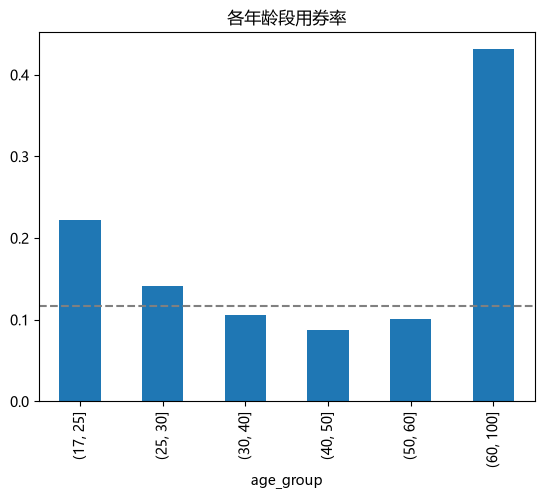

In [12]:
# 分段边界可以自己改着试（左开右闭），例如 [17, 25, 30, 40, 50, 60, 100]
age_bins = [17, 25, 30, 40, 50, 60, 100]
df['age_group'] = pd.cut(df['age'], bins=age_bins)

age_rate = df.groupby('age_group', observed=True)['coupon_ind'].agg(用券率='mean', 人数='size')
print(age_rate.round(3))

chi2, p, dof, _ = chi2_contingency(pd.crosstab(df['age_group'], df['coupon_ind']))
print(f'卡方 p 值 = {p:.2e}')
print(f"Cramér's V = {cramers_v(df['age_group'], df['coupon_ind']):.3f}")

age_rate['用券率'].plot(kind='bar', title='各年龄段用券率')
plt.axhline(base_rate, color='grey', linestyle='--');

In [13]:
# 各变量和用券的关联强度排名（Cramér's V）
v_rank = pd.Series({col: cramers_v(df[col], df['coupon_ind']) for col in cat_cols + ['age_group']}).sort_values(ascending=False)
print(v_rank.round(3))

age_group    0.180
returned     0.143
job          0.137
loan         0.065
marital      0.060
default      0.024
dtype: float64


**你的结论：** 对比 3.2 和 3.3：只看平均年龄，和按年龄分段看用券率，结论一样吗？为什么？两列用券次数和用券的关系如何？\
结论不太一样，按平均年龄看会发现用券和不用券的分别是41.81和40.82。但按年龄分段来看会发现最高的两端是(17,25]，(60,100]。平均年龄看会发现用券和不用券的区别不大是因为用券组里年轻人和老年人占比高，一个拉低平均年龄、一个拉高，正好抵消，所以平均值看不出差别，这也符合年龄分段两端高的现象\
上个月用券组 0.54 次，没用券组 0.26 次，用券组高；近 6 个月：用券组 2.12 次，没用券组 2.86 次，没用券组高，可能是因为上个月活动或着放假拉动了使用率（推测）？

## 4. 逻辑回归建模

### 4.1 特征准备
- 类别变量做独热编码（drop_first=True：每个变量去掉一类作为“基准类”，其他类的系数都和它比较）
- 年龄用 3.3 的分段 age_group（年龄是两头高、中间低，直接用数字，逻辑回归只能学到单一方向）
- ID 不进模型；coupon_ind 是答案 y
- 分层抽样：70% 训练、30% 测试，两边用券比例一致

In [14]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix

feature_cols = ['job', 'marital', 'default', 'returned', 'loan', 'age_group',
                'coupon_used_in_last6_month', 'coupon_used_in_last_month']
# age_group 是区间类型，先转成文字再独热编码
X = pd.get_dummies(df[feature_cols].astype({'age_group': str}), drop_first=True, dtype=int)
y = df['coupon_ind']
print('特征矩阵形状：', X.shape)
X.head()

特征矩阵形状： (25317, 23)


,coupon_used_in_last6_month,coupon_used_in_last_month,job_blue-collar,job_entrepreneur,job_housemaid,job_management,job_retired,job_self-employed,job_services,job_student,...,marital_married,marital_single,default_yes,returned_yes,loan_yes,"age_group_(25, 30]","age_group_(30, 40]","age_group_(40, 50]","age_group_(50, 60]","age_group_(60, 100]"
0,2,0,0,0,0,1,0,0,0,0,...,1,0,0,1,0,0,0,1,0,0
1,1,1,0,0,0,0,0,0,0,0,...,0,0,0,1,0,0,0,1,0,0
2,2,0,0,0,0,0,0,0,0,0,...,1,0,0,1,1,0,0,1,0,0
3,2,0,0,0,0,1,0,0,0,0,...,0,1,0,1,1,1,0,0,0,0
4,5,0,0,0,0,0,0,0,0,0,...,0,0,0,1,0,0,0,1,0,0


In [15]:
# stratify=y：分层抽样；random_state 固定随机种子，保证结果可复现
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)
print('训练集用券率：', round(y_train.mean(), 3), '  测试集用券率：', round(y_test.mean(), 3))

训练集用券率： 0.117   测试集用券率： 0.117


### 4.2 训练模型，先看准确率和混淆矩阵

In [16]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)   # 默认阈值 0.5：预测概率 > 0.5 判为“会用券”

print('模型准确率：', round(accuracy_score(y_test, y_pred), 3))
print('全猜“不用券”的准确率：', round(1 - y_test.mean(), 3))

模型准确率： 0.882
全猜“不用券”的准确率： 0.883


In [17]:
# 混淆矩阵：行是真实情况，列是模型预测
cm = pd.DataFrame(confusion_matrix(y_test, y_pred),
                  index=['真实：不用券', '真实：用券'],
                  columns=['预测：不用券', '预测：用券'])
cm

,预测：不用券,预测：用券
真实：不用券,6671,37
真实：用券,859,29


**你的结论：** 模型的准确率和"全猜不用券"比，强了多少？看混淆矩阵第二行：测试集里真正用券的人，模型找出来了几个？这个模型能直接拿去发券吗？
模型准确率低于全猜“不用券”的准确率。真实用券的是 888 人（859 + 29），模型漏掉了 859 人，只找出 29 人。绝对不能使用。

## 4.3 提高召回率：降低阈值 vs class_weight

两种办法让模型多找出用券的人：
- 降低阈值：模型不变，只把“判为用券”的门槛从 0.5 往下调
- class_weight='balanced'：训练时加大少数类（用券）的权重，模型本身会变

In [18]:
from sklearn.metrics import precision_score, recall_score, roc_auc_score, RocCurveDisplay

# 每个测试用户“会用券”的预测概率（第二列是类别 1 的概率）
proba = model.predict_proba(X_test)[:, 1]

def evaluate(y_true, y_pred, 名称):
    # 召回率：真正用券的人里，模型找出了多少；精确率：模型说会用券的人里，真用券的占多少
    print(f'【{名称}】')
    print('准确率：', round(accuracy_score(y_true, y_pred), 3))
    print('召回率：', round(recall_score(y_true, y_pred), 3))
    print('精确率：', round(precision_score(y_true, y_pred, zero_division=0), 3))
    cm = pd.DataFrame(confusion_matrix(y_true, y_pred),
                      index=['真实：不用券', '真实：用券'],
                      columns=['预测：不用券', '预测：用券'])
    print(cm)
    print()

In [19]:
# 同一个模型，换不同阈值：概率 >= 阈值 就判为“会用券”
rows = []
for t in [0.5, 0.3, 0.2, 0.15, 0.1]:
    pred_t = (proba >= t).astype(int)
    rows.append({'阈值': t,
                 '准确率': accuracy_score(y_test, pred_t),
                 '召回率': recall_score(y_test, pred_t),
                 '精确率': precision_score(y_test, pred_t, zero_division=0),
                 '预测为用券人数': pred_t.sum()})
pd.DataFrame(rows).round(3)

,阈值,准确率,召回率,精确率,预测为用券人数
0,0.50,0.882,0.033,0.439,66
1,0.30,0.875,0.166,0.411,358
2,0.20,0.844,0.350,0.338,921
3,0.15,0.765,0.507,0.251,1794
4,0.10,0.600,0.705,0.184,3400


In [20]:
# 每个阈值：发多少券、找到多少用券者，以及“比上一行多发的券”的命中率
rows = []
for t in [0.5, 0.3, 0.2, 0.15, 0.1]:
    pred = (proba >= t)
    rows.append({'阈值': t, '发券数': pred.sum(), '找到用券者': (pred & (y_test == 1)).sum()})
cmp = pd.DataFrame(rows)
cmp['新增券数'] = cmp['发券数'].diff()
cmp['新增找到'] = cmp['找到用券者'].diff()
cmp['新增券命中率'] = (cmp['新增找到'] / cmp['新增券数']).round(3)
print('随机发券命中率（整体用券率）：', round(y_test.mean(), 3))
cmp

随机发券命中率（整体用券率）： 0.117


,阈值,发券数,找到用券者,新增券数,新增找到,新增券命中率
0,0.50,66,29,NaN,NaN,NaN
1,0.30,358,147,292.0,118.0,0.404
2,0.20,921,311,563.0,164.0,0.291
3,0.15,1794,450,873.0,139.0,0.159
4,0.10,3400,626,1606.0,176.0,0.110


In [21]:
# class_weight='balanced'：按类别人数的反比给权重，用券的人少，权重就大
model_bal = LogisticRegression(max_iter=1000, class_weight='balanced')
model_bal.fit(X_train, y_train)
evaluate(y_test, model_bal.predict(X_test), 'class_weight=balanced，阈值 0.5')

【class_weight=balanced，阈值 0.5】
准确率： 0.677
召回率： 0.639
精确率： 0.21
        预测：不用券  预测：用券
真实：不用券    4579   2129
真实：用券      321    567



原模型 AUC： 0.713
balanced 模型 AUC： 0.713


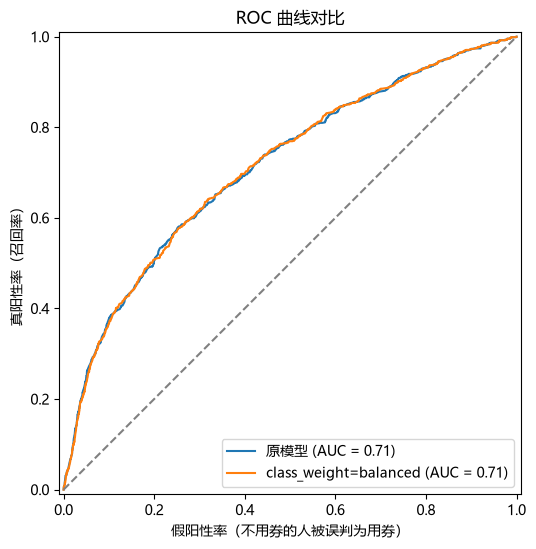

In [22]:
# AUC：不依赖阈值，衡量模型把用券者排在不用券者前面的能力（0.5 = 瞎猜，1 = 完美）
proba_bal = model_bal.predict_proba(X_test)[:, 1]
print('原模型 AUC：', round(roc_auc_score(y_test, proba), 3))
print('balanced 模型 AUC：', round(roc_auc_score(y_test, proba_bal), 3))

# 两条 ROC 曲线画在同一张图上
fig, ax = plt.subplots(figsize=(6, 6))
RocCurveDisplay.from_predictions(y_test, proba, name='原模型', ax=ax)
RocCurveDisplay.from_predictions(y_test, proba_bal, name='class_weight=balanced', ax=ax)
ax.plot([0, 1], [0, 1], color='grey', linestyle='--')   # 对角线：瞎猜
ax.set_title('ROC 曲线对比')
ax.set_xlabel('假阳性率（不用券的人被误判为用券）')
ax.set_ylabel('真阳性率（召回率）');

**你的结论：**
1. 阈值降低后，召回率、精确率、准确率分别怎么变？和你之前的预测一致吗？\
   召回率升高，精确率降低，准确率降低。预测一致
2. 两个模型的 AUC 差多少？class_weight 主要改变了什么？\
   AUC没有变化，class_weight改变了权重，它相当于降低普通模型的分类阈值，使模型更倾向于预测“会用券”，从而提高召回率，但同时降低精确率。但并没有让模型更会区分用券的人（两个模型的 AUC 都是 0.713）
3. 如果发一张券成本很低、漏掉一个用券者损失更大，你选哪个阈值？为什么？\
   按题目前提（券便宜、漏人损失大），我选阈值 0.15。\
   为什么不更高（0.2）：从 0.2 降到 0.15，多发 873 张，新增命中率 0.159，仍高于随机的 0.117，这些券还值得发。\
   为什么不更低（0.1）：从 0.15 降到 0.1，多发 1606 张，新增命中率 0.110，约等于随机，模型在这一档已经不起作用了。\
   模型的价值和前提：在我选的阈值下，整体命中率约 0.251，约是随机的 2.1 倍（lift）。阈值取决于券的成本，券贵就停在 0.2。每档新增的人数不多，比例有波动，上线前要用实验再确认。

## 5. 业务建议与 A/B 实验设计

### 5.1 业务建议
- **发给谁**：用第 4 步的模型给每个用户打分，按阈值 0.15 选人。测试集上这样发 1794 张券，能找到约一半的用券者（召回率 0.507），命中率约 25%，是随机发券的 2.1 倍。
- **重点人群**：第 3 步发现学生、60 岁以上用户、近期没有退货的用户用券率明显更高，可以优先覆盖。
- **但要先验证**：模型只能说明"谁可能用券"，不能说明"是不是券让他买的"。有些人不发券也会买，给他们发券等于白白让利。所以正式推广前先做 A/B 实验，确认发券真的带来了额外购买。

### 5.2 实验分组
- 实验对象：模型选出的用户（阈值 0.15）。
- 把这些人**随机**分成两组：A 组（实验组）发券，B 组（对照组）不发。一段时间后比较两组的表现，两组的差就是发券带来的增量。
- 为什么要随机：随机分组能让两组在年龄、职业这些看得到的特征上，以及收入变化、购物需求这些看不到的因素上平均一致，唯一的区别就是有没有券。
- 为什么不拿"模型没选中的人"做对照：这些人本来就不太会买，拿他们比较会把人群本身的差异误当成券的效果。
- 和第 4 步训练集/测试集划分的区别：那次划分是检验模型**预测**得准不准，两组待遇一样；A/B 实验是检验发券有没有**因果**效果，两组待遇不同。

### 5.3 指标
- **核心指标：人均利润** =（销售额 − 商品成本 − 券的成本）÷ 组内总人数。要除以全组人数，而不是只除以下单的人，这样两组才可比。
- **辅助指标**：购买率、客单价，用来解释利润为什么变了。比如购买率上升但客单价下降，说明券可能只带来了低价订单。
- **护栏指标**（不能明显变差）：
  - 退货率：防止用户为了凑单买了不需要的东西，收到后再退。
  - 停券后复购率：实验结束后继续观察一段时间，看 A 组用户没有券时是否还会购买，防止养成"没券不买"的习惯。

### 5.4 样本量
- 人越多，运气带来的波动越小，越能分清两组的差别是券的作用还是运气。
- 想检测的效果越小，需要的人越多，而且增长很快（见下方计算）。
- 每组如果只有约 900 人（1794 人的一半），只能检测出约 4.6 个百分点以上的提升。如果券的真实效果只有 1～2 个点，实验很可能得出"没有效果"的结论，但原因其实是人不够。
- 所以实验前要先和业务方确定**最小可检测效应（MDE）**：效果至少多大才值得发券，再据此算人数。人数不够就扩大实验范围，或者接受只能检测较大的效果。
- 说明：这里用整体用券率 11.7% 作为基准粗略估算。实际实验对象是模型选中的人，基准会不一样，上线前应该用对照组的实际数据重新计算。

In [23]:
# 5.4 样本量估算：两组比例的差异检验（显著性水平 0.05，把握度 80%）
from scipy.stats import norm
import math

def sample_size(p1, p2, alpha=0.05, power=0.8):
    """检测出购买率从 p1 变到 p2，每组需要多少人"""
    z_a = norm.ppf(1 - alpha / 2)
    z_b = norm.ppf(power)
    p_bar = (p1 + p2) / 2
    n = (z_a * math.sqrt(2 * p_bar * (1 - p_bar))
         + z_b * math.sqrt(p1 * (1 - p1) + p2 * (1 - p2))) ** 2 / (p2 - p1) ** 2
    return math.ceil(n)

base = 0.117  # 基准：整体用券率
pd.DataFrame([
    {'B组购买率': base, 'A组购买率': p2,
     '提升(百分点)': round((p2 - base) * 100, 1),
     '每组所需人数': sample_size(base, p2)}
    for p2 in [0.13, 0.15, 0.17]
])

,B组购买率,A组购买率,提升(百分点),每组所需人数
0,0.117,0.13,1.3,10054
1,0.117,0.15,3.3,1667
2,0.117,0.17,5.3,686


In [24]:
# 每组 900 人时，最小能检测出多大的提升（MDE）
p2 = base + 0.001
while sample_size(base, p2) > 900:
    p2 += 0.001
print(f'每组 900 人，最小可检测提升约 {(p2 - base) * 100:.1f} 个百分点（{base:.1%} → {p2:.1%}）')

每组 900 人，最小可检测提升约 4.6 个百分点（11.7% → 16.3%）


### 5.5 风险及应对
| 风险 | 说明 | 应对 |
|---|---|---|
| 组间污染 | A 组用户把券转给 B 组的亲友，B 组不再是"没券"的状态 | 券不可转让；必要时按城市或社群整组分配 |
| 券码外传 | 券码被公开分享，任何人都能用 | 一人一码，绑定账号 |
| 时间因素 | 节假日、大促会让购买量整体波动 | A、B 两组同时进行，影响相同；尽量避开大促，至少跑满一周，结论注明适用时期 |
| 多账号重复参与 | 同一人用多个账号，可能同时在两组 | 按设备、手机号去重 |
| 券存量不足 | A 组部分用户没领到券 | 分析时仍按原本分到的组计算，不剔除没领到的人，否则两组就不再是随机的 |
| 恶意刷单 | 异常订单拉高购买数据 | 用风控规则剔除异常订单，两组用同一套规则 |

**AI 辅助说明（第 5 步）**：第 5 步的思路来自我和 AI 的问答（增量、随机分组、指标、样本量、风险都是我先回答，AI 补充和纠正），文字由 AI 按我的回答整理润色，样本量计算代码由 AI 编写。我纠正过的理解：一开始以为"人越多效果越好"，实际是人越多越能**看清**小的效果，不会让效果本身变大。

## 6. AI 辅助记录

这个项目用 AI（Claude）做辅助：代码框架由 AI 写，结论由我自己运行、验证后写。第 5 节的文字由 AI 按我的口头回答整理。下面记录过程中 AI 的建议和我的判断，哪些我验证后采纳，哪些是错的。

| 步骤 | 情况 | 我怎么验证 | 结论 |
|---|---|---|---|
| 2.2 | 我想把 job 里的 unknown 改成"自由职业者"，AI 建议保留为单独类别 | unknown 只有 163 条，没有依据说明它们是自由职业者，硬改等于编造数据 | 采纳 AI 建议 |
| 3 | 我想用方差分析比较用券组和年龄，AI 指出应该用卡方检验（年龄分段 vs 是否用券） | 方差分析比较的是多组的均值，而这里两个变量都是类别型 | 采纳，是我错了 |
| 3.3 | AI 用"一半 20 岁、一半 60 岁"举例，我据此写成"用券组里年轻人和老年人最多" | 回看分段用券率，应该是年轻人和老年人"用券率更高"，而不是人数最多 | AI 的例子有误导，已改正 |
| 4.3 | 我以为 class_weight='balanced' 能提高准确率 | 两个模型 AUC 都是 0.713，balanced 的召回率落在原模型阈值 0.15 和 0.1 之间 | 我错了：它只相当于降低阈值，模型区分能力没变 |
| 4.3 | 我一开始选阈值 0.1，理由是召回率最高 | 算了每降一档新增券的命中率：0.15→0.1 那一档只有 0.110，约等于随机的 0.117 | 改选 0.15 |
| 5.4 | 我以为"实验人数越多，效果越好" | 券的真实效果是固定的，人数只决定实验能看清多小的差别 | 我理解错了：人越多越能看清小的效果，但不会让效果变大 |